# Ders 03 · Hibrit PINN — fizik ile seyrek ölçümü aynı kayba koymak

**Kolay PINN · Türkişi Engineering** · Lisans + yüksek lisans · Adım 6

Ders 02'deki forward PINN'e bir terim ekliyoruz: birkaç noktadaki **gürültülü ölçüm**. Ölçümleri FDM çözümünden
(CFD yerine geçen referans) alıp gürültü ekleyerek üretiyoruz:

$$
\mathcal{L} = \underbrace{\mathcal{L}_{\mathrm{PDE}} + \lambda\,\mathcal{L}_{\mathrm{Robin}}}_{\text{fizik}}
\;+\; \mu\,\underbrace{\frac{1}{N_d}\sum_{i=1}^{N_d}\big(\hat\theta(\mathbf{x}_i) - \theta_i^{\mathrm{ö}}\big)^2}_{\text{veri}},
\qquad
\theta_i^{\mathrm{ö}} = \theta_{\mathrm{FDM}}(\mathbf{x}_i) + \varepsilon_i,\quad \varepsilon_i \sim \mathcal{N}(0, \sigma^2)
$$

Sorduğumuz soru: **veri ne zaman işe yarar?** İki durum deneyeceğiz:
1. fizik doğru (Bi = 4.895) — veri bir şey katar mı?
2. fizik yanlış (model Bi = 2 sanıyor) — veri hatayı düzeltir mi?

**Öğrenme hedefleri**
1. Veri terimini kayba eklemek ve ağırlığını (μ) ölçekle seçmek
2. Sensör sayısı, yerleşim ve gürültünün etkisini tohum aralığıyla birlikte okumak
3. Fiziğin gürültüyü nasıl süzdüğünü göstermek
4. Verinin değerini model hatasıyla karşılaştırarak tahmin etmek *(yüksek lisans derinliği)*

> Defterdeki eğitimler kısaltılmıştır (her biri ~2 dk, CPU). Tam koşular `runs/hyb_*` ve `runs/wrongbi_*` klasörlerinden yüklenir.

In [1]:
import sys, json, time, logging, warnings
from pathlib import Path
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=UserWarning)

CASE = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
ROOT = CASE.parents[1]
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(CASE))

import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import Image, display

from kolay_pinn.style import use_slide_style, C, INK, MUTED, cmap_thermal
from fdm_solver import BI_DEFAULT as Bi, solve_fdm, T_WALL, T_INF
# Ders 02'de adım adım yazdığımız bileşenler artık modül:
from pinn_forward import MLP, theta_hat, residuals, collocation, evaluate
from pinn_hybrid import sensors

use_slide_style(); plt.rcParams["figure.dpi"] = 110
torch.set_default_dtype(torch.float64)
ASSETS = CASE / "lecture" / "ders03" / "assets"
def goster(ad, genislik=760):
    display(Image(filename=str(ASSETS / ad), width=genislik))

print(f"torch {torch.__version__} · gerçek Bi = {Bi:.3f}")

torch 2.15.0+cu132 · gerçek Bi = 4.895


---
## 1 · Veriyi kayba ekle

### 1.1 Sanal sensörler

FDM ($N = 201$) iç düğümlerinden 20 nokta seçip $\sigma = 0.01$ gürültü ekliyoruz. Boyutlu karşılığı:

$$\sigma_T = \sigma\,(T_w - T_\infty) = 0.01 \times 50 = 0.5\ ^\circ\mathrm{C}$$

— tipik bir termokupl belirsizliği.

In [2]:
sigma = 0.01
X_d, y_d, temiz = sensors(20, "uniform", sigma, seed=0)
print(f"{len(X_d)} sensör · gürültü RMS = {np.sqrt(np.mean((y_d - temiz)**2)):.4f}  ({(T_WALL - T_INF) * sigma:.1f} °C)")
print("ilk üç ölçüm (θ):", np.round(y_d[:3], 4), " gerçek:", np.round(temiz[:3], 4))

20 sensör · gürültü RMS = 0.0092  (0.5 °C)
ilk üç ölçüm (θ): [0.9121 0.9439 0.8702]  gerçek: [0.899  0.9469 0.8659]


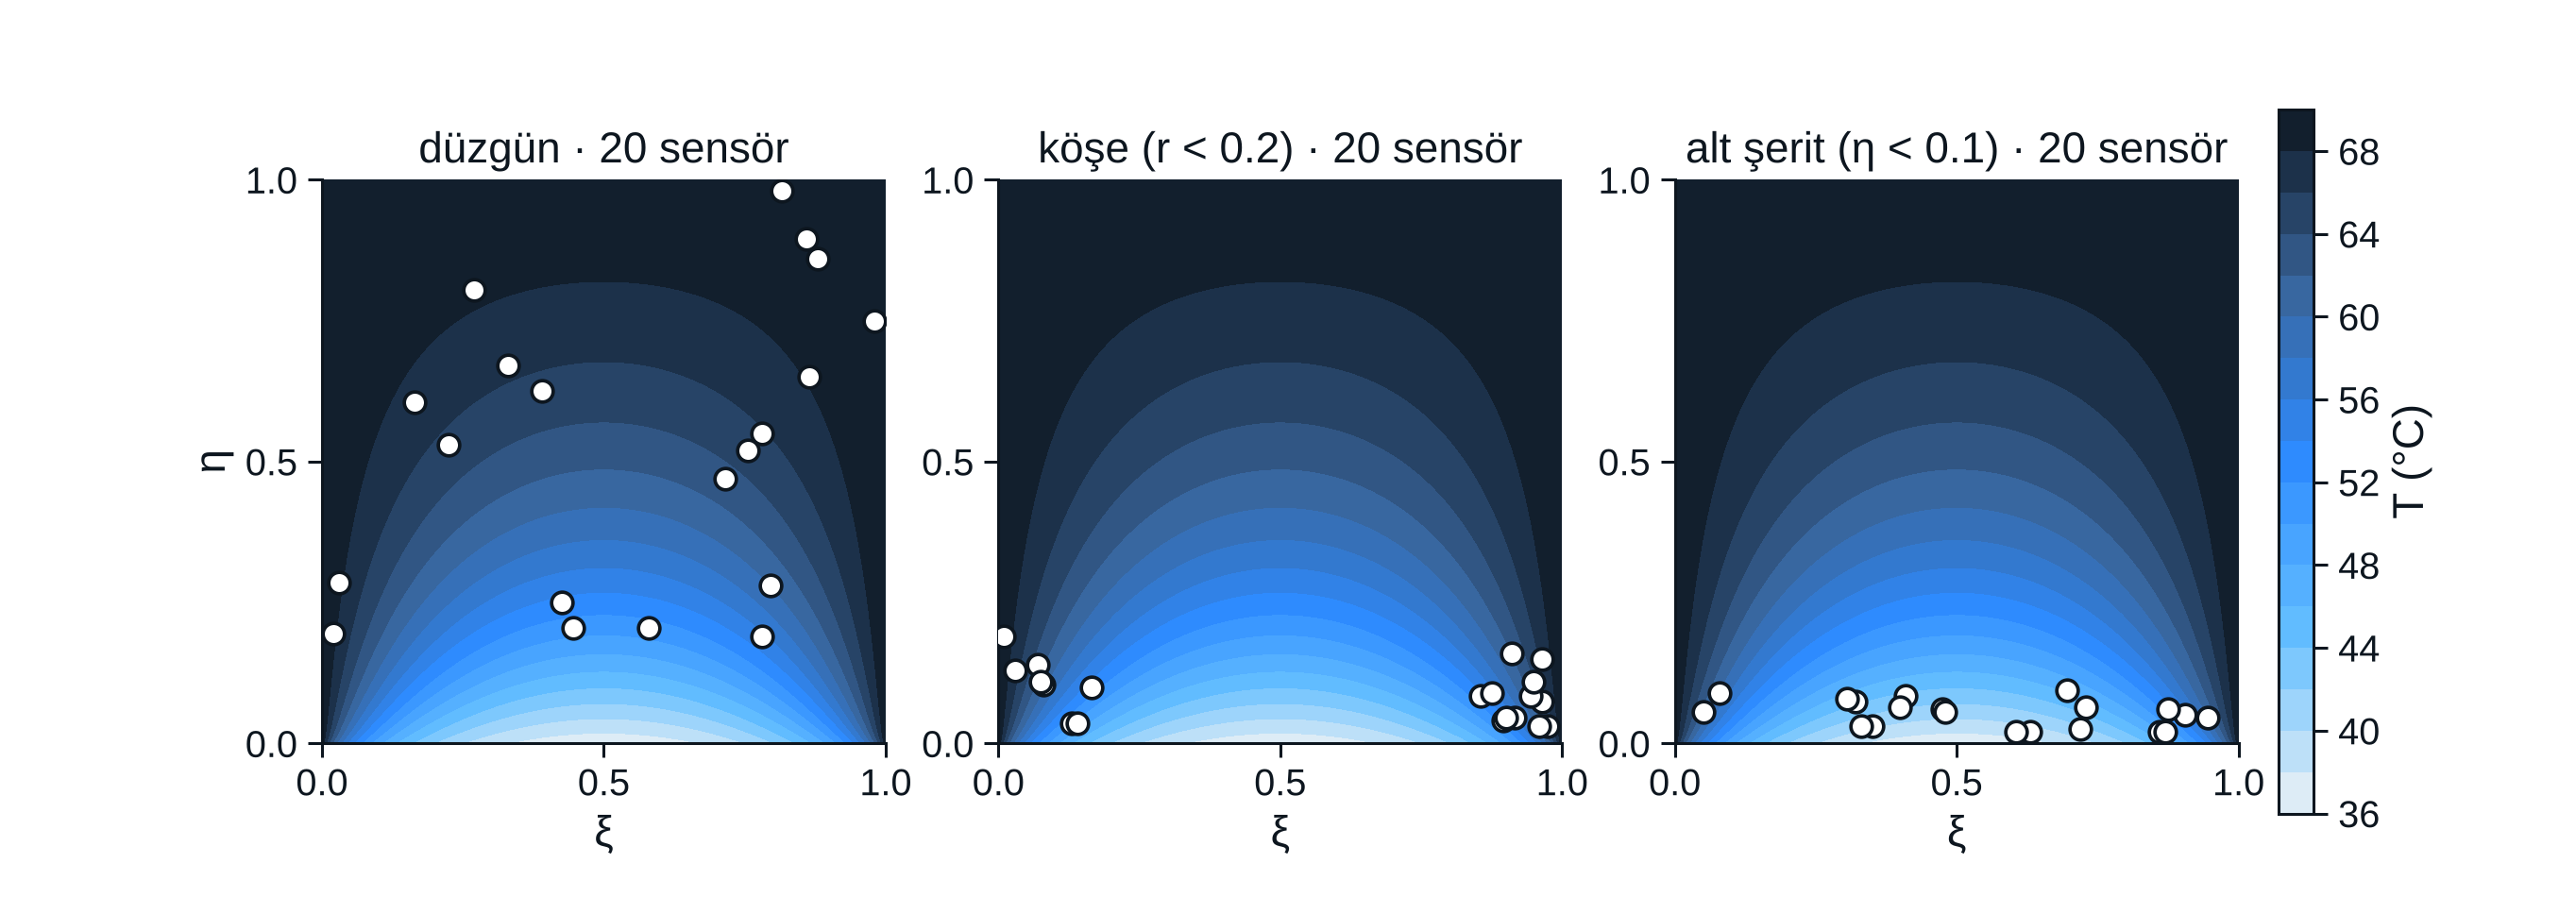

In [3]:
goster("01_sensors.png", 900)

### 1.2 Hibrit kayıp

Ders 02'nin `residuals` fonksiyonuna tek bir terim ekliyoruz. `bi_model` parametresi, modelin **inandığı** Biot
sayısı; bölüm 3'te onu bilerek yanlış vereceğiz.

In [4]:
def hibrit_kayip(model, X_int, X_bot, Xd, yd, mu=1.0, bi_model=Bi, lam=1.0):
    r_pde, r_rob = residuals(model, X_int, X_bot, bi_model)
    l_pde, l_rob = (r_pde**2).mean(), (r_rob**2).mean()
    l_dat = ((theta_hat(model, Xd) - yd)**2).mean() if len(Xd) else torch.zeros(())
    return l_pde + lam * l_rob + mu * l_dat, l_pde, l_rob, l_dat

def egit(Xd, yd, mu=1.0, bi_model=Bi, seed=0, ADAM=1500, LBFGS=300):
    torch.manual_seed(seed)
    model = MLP(50, 4)
    X_int, X_bot = collocation(4096, 256, False, seed, 0.0)
    Xd, yd = torch.tensor(Xd), torch.tensor(yd)[:, None]
    f = lambda: hibrit_kayip(model, X_int, X_bot, Xd, yd, mu, bi_model)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    sch = torch.optim.lr_scheduler.ExponentialLR(opt, gamma=0.1 ** (1 / ADAM))
    t0 = time.perf_counter()
    for it in range(ADAM):
        opt.zero_grad(); L = f()[0]; L.backward(); opt.step(); sch.step()
    lb = torch.optim.LBFGS(model.parameters(), lr=1.0, max_iter=LBFGS, history_size=50, line_search_fn="strong_wolfe",
                           tolerance_grad=1e-11, tolerance_change=1e-14)
    def closure():
        lb.zero_grad(); L = f()[0]; L.backward(); return L
    lb.step(closure)
    L, lp, lr, ld = f()
    m = evaluate(model, Bi)[0]           # gerçek Bi'ye karşı doğrula
    print(f"μ = {mu:g}, Bi_model = {bi_model:.3g}, N_d = {len(Xd)}:  L = {L.item():.2e} "
          f"(PDE {lp.item():.1e}, Robin {lr.item():.1e}, veri {ld.item():.1e}) · bağıl L2 = {m['rel_L2']:.2e} · "
          f"Q hatası %{100 * m['Q_rel_err']:.2f} · {time.perf_counter() - t0:.0f} s")
    return model, m

### 1.3 Ölçek: μ = 1 ne kadar güçlü?

Ağ ölçümlere gürültü düzeyinde uyarsa veri terimi $\approx \sigma^2 = 10^{-4}$ olur. Ders 02'de Robin kaybının
köşe çelişkisi yüzünden $\approx 0.08$'de kaldığını görmüştük:

$$\mathcal{L}_{\mathrm{veri}} \approx \sigma^2 = 10^{-4} \quad\ll\quad \mathcal{L}_{\mathrm{Robin}} \approx 0.08$$

$\mu = 1$ ile veri terimi toplam kaybın binde birinden az. Bu yüzden $\mu = 100$'ü de deniyoruz.

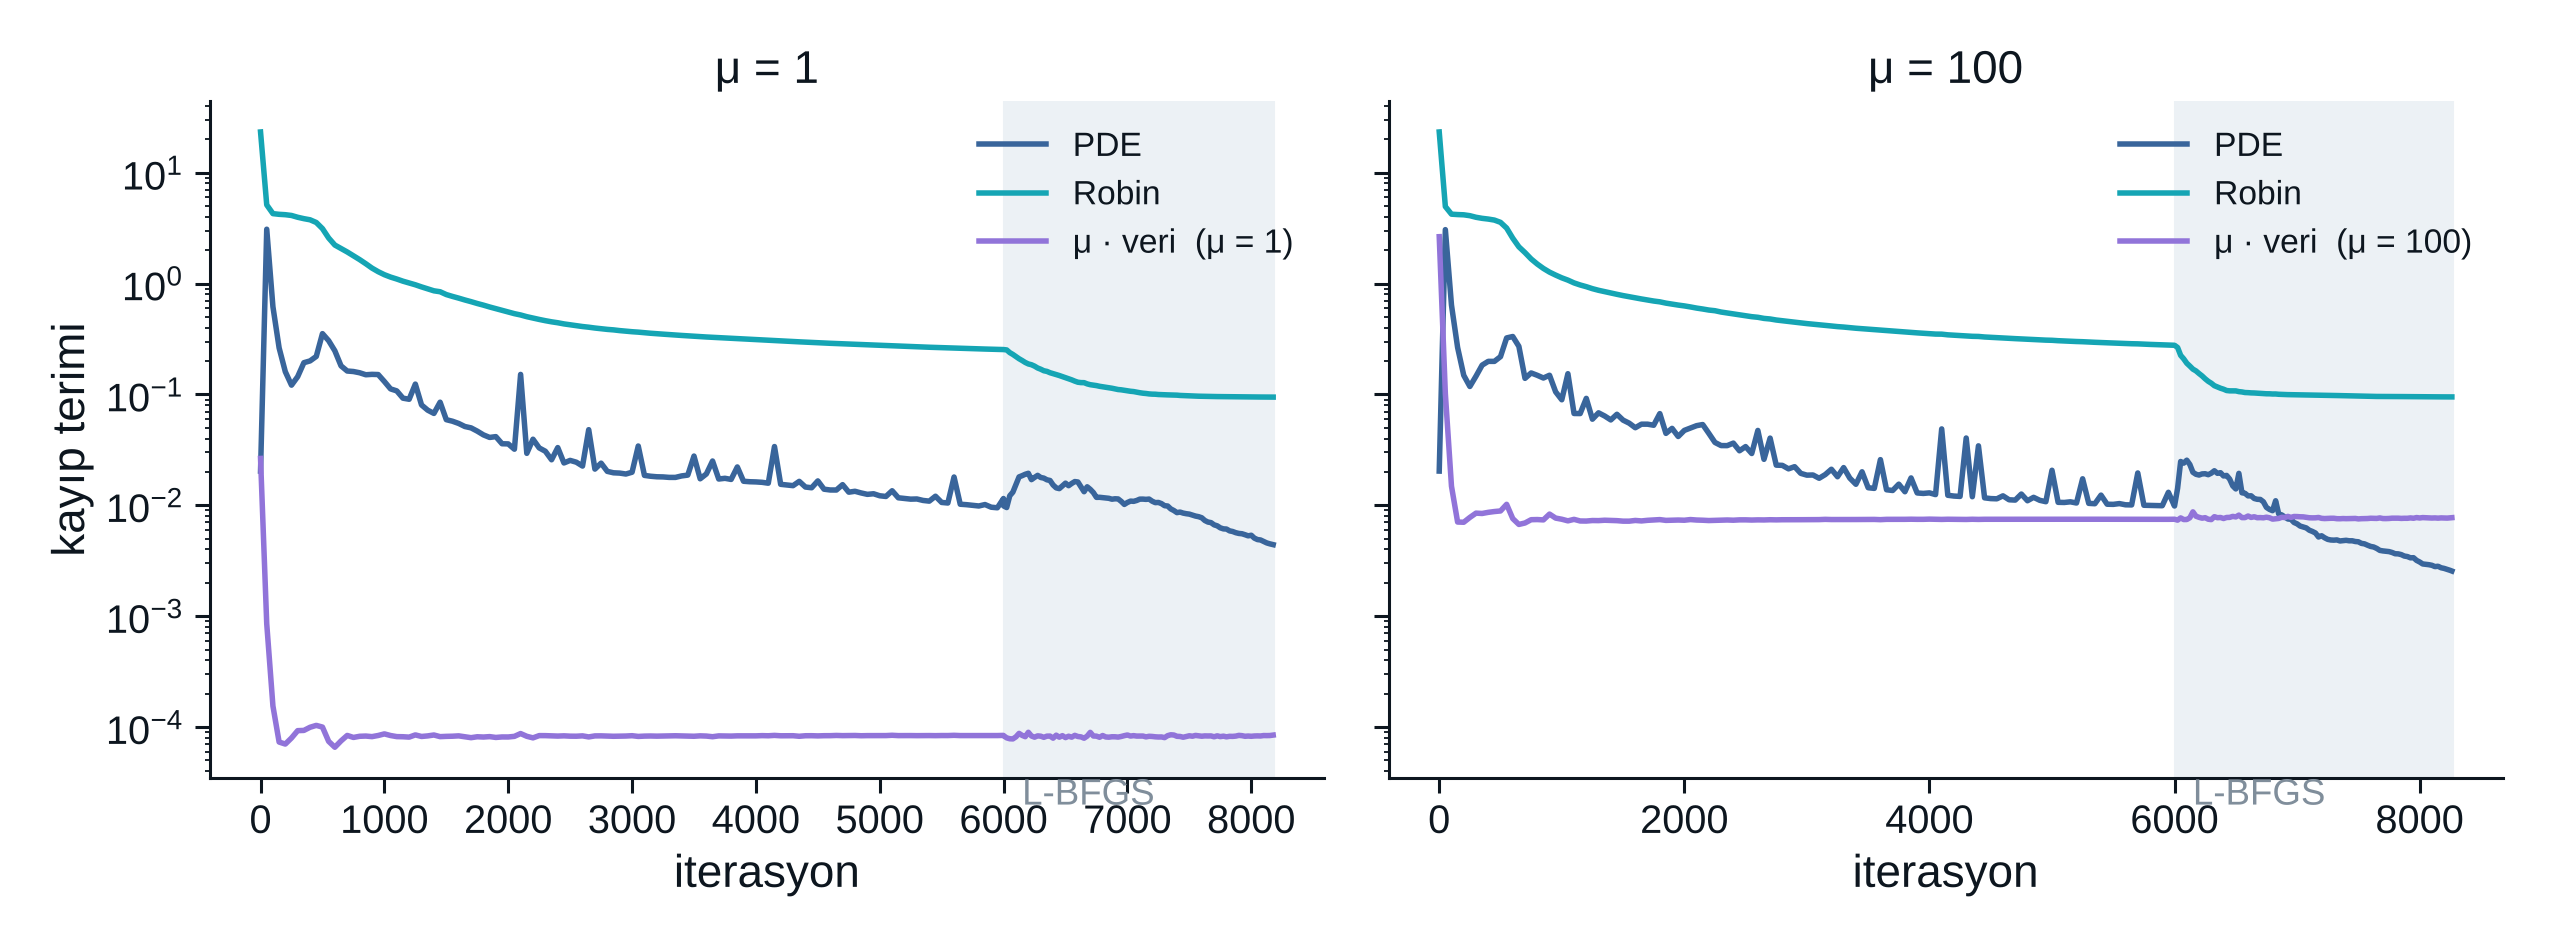

In [5]:
goster("02_loss_terms.png", 900)

---
## 2 · Doğru fizik: veri ne katar?

Önce kısa bir eğitim: doğru Bi ve 20 sensör.

In [6]:
model_h, m_h = egit(X_d, y_d, mu=1.0)

μ = 1, Bi_model = 4.89, N_d = 20:  L = 4.96e-01 (PDE 6.8e-02, Robin 4.3e-01, veri 8.6e-05) · bağıl L2 = 2.37e-03 · Q hatası %0.27 · 107 s


Tam koşulardan (6000 Adam + 2000 L-BFGS, üç tohum) özet. Gri bant, Ders 02'nin **veri yok** koşularının tohum aralığı:

In [7]:
S = json.loads((CASE / "data" / "summary_hybrid.json").read_text())
b = S["count"]["0"]["rel_L2"]
print(f"veri yok (N_d = 0): bağıl L2 aralığı [{b['min']:.1e}, {b['max']:.1e}]\n")
print(f"{'grup':22s} {'geo. ort.':>10s} {'min':>9s} {'max':>9s} {'oran':>6s}")
for blok in ("count", "config"):
    for g, v in S[blok].items():
        r = v["rel_L2"]
        ad = f"N_d = {g}" if blok == "count" else g
        print(f"{ad:22s} {r['gmean']:10.2e} {r['min']:9.1e} {r['max']:9.1e} {r['gmean'] / b['gmean']:6.2f}")

veri yok (N_d = 0): bağıl L2 aralığı [2.4e-04, 9.5e-04]

grup                    geo. ort.       min       max   oran
N_d = 0                  4.19e-04   2.4e-04   9.5e-04   1.00
N_d = 5                  6.44e-04   3.7e-04   9.2e-04   1.54
N_d = 20                 5.86e-04   4.1e-04   9.6e-04   1.40
N_d = 80                 5.11e-04   3.3e-04   1.0e-03   1.22
düzgün, μ = 1            5.86e-04   4.1e-04   9.6e-04   1.40
köşe, μ = 1              4.25e-04   3.0e-04   8.2e-04   1.01
alt şerit, μ = 1         4.59e-04   3.1e-04   8.1e-04   1.10
düzgün, μ = 100          1.11e-03   5.7e-04   1.6e-03   2.64


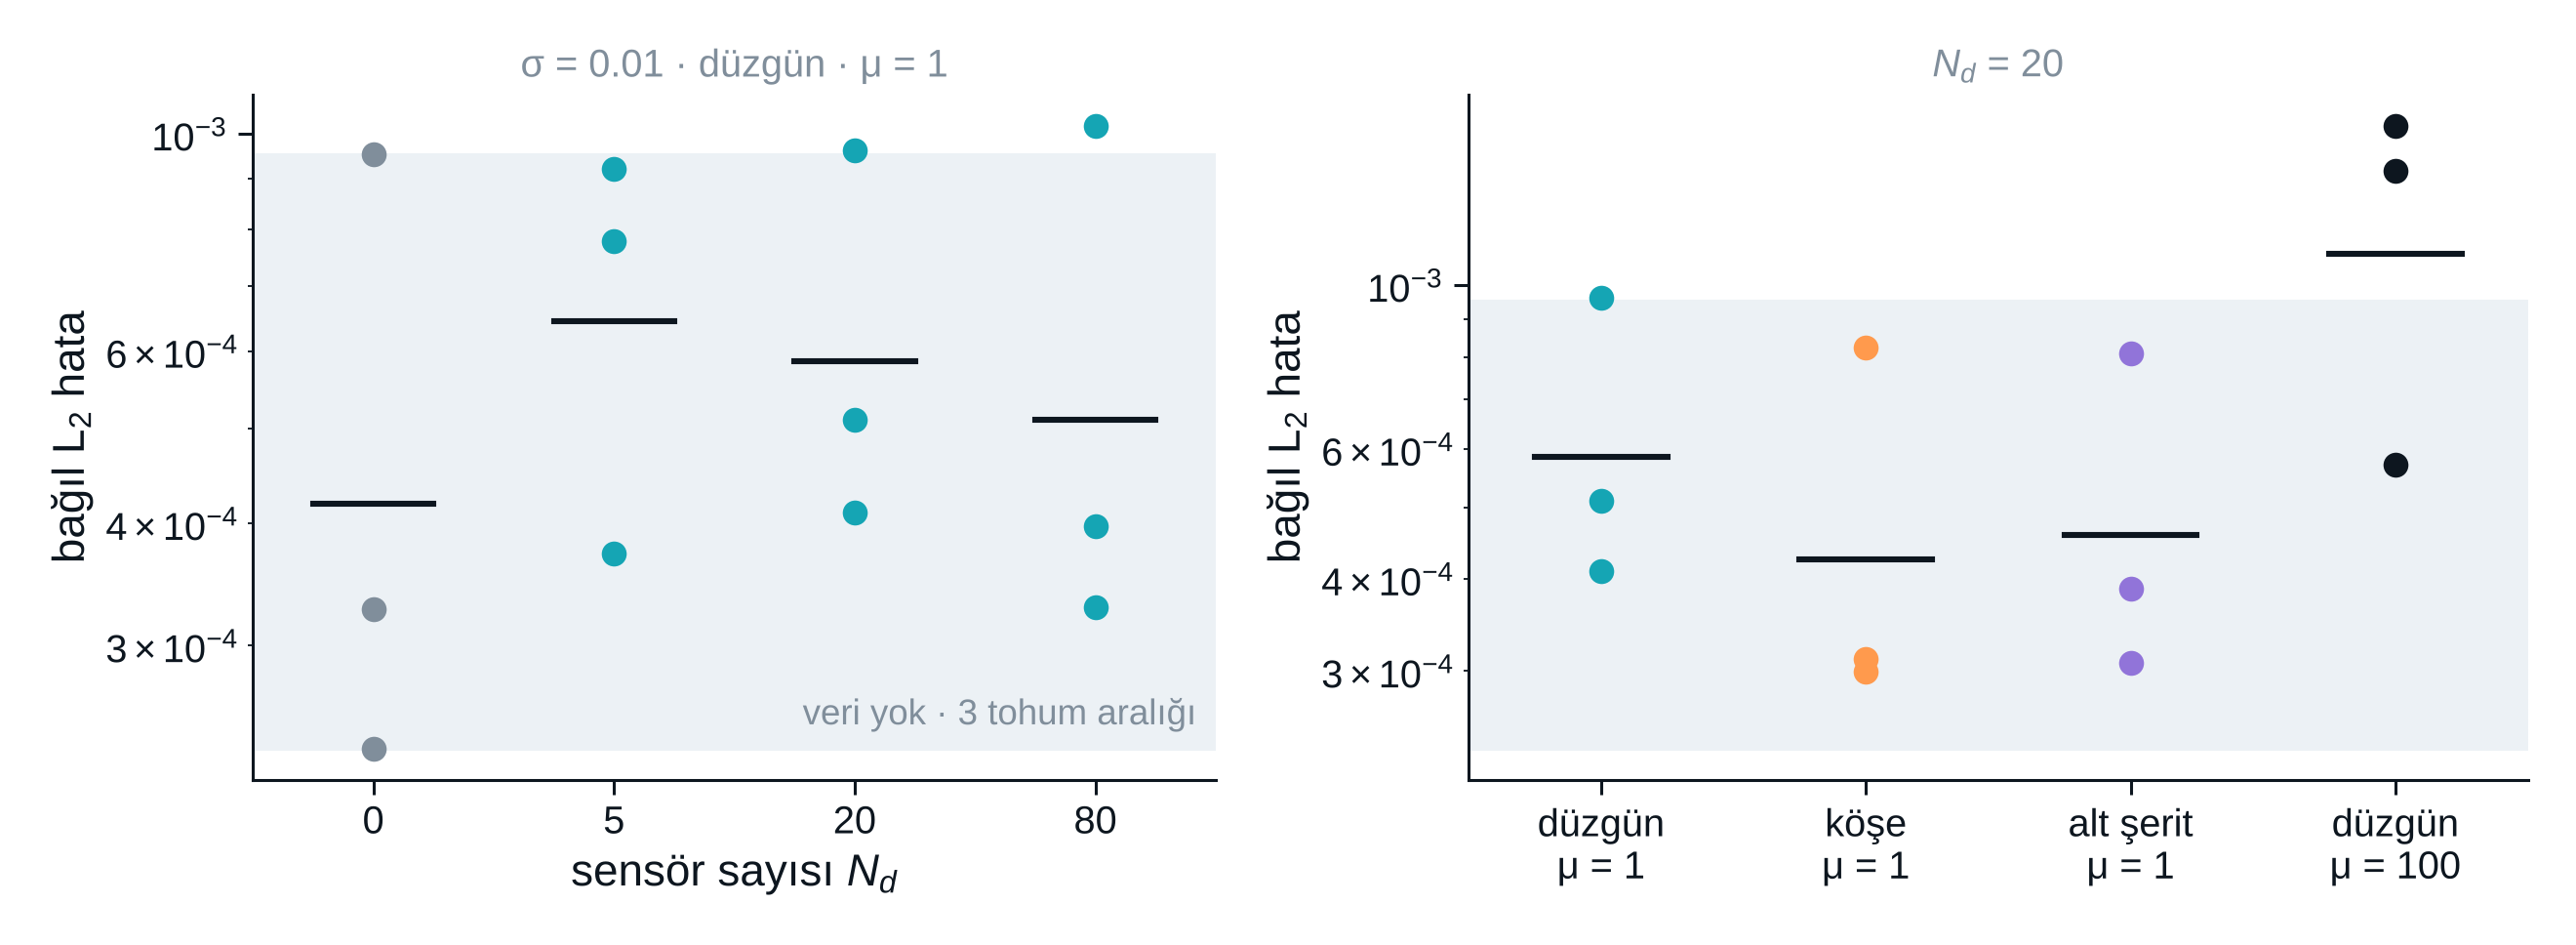

In [8]:
goster("03_count_config.png", 900)

**Okuma.** Sensör sayısı ve yerleşimi hatayı veri yok koşularının tohum aralığının dışına taşımıyor; $\mu = 100$ ise
hatayı artırıyor. Neden? Gürültüye bakalım.

### 2.1 Fizik gürültüyü süzer

Ağın sensörlerdeki değerini hem **gürültülü ölçümle** hem **gerçek** değerle karşılaştırıyoruz:

In [9]:
with torch.no_grad():
    fit = theta_hat(model_h, torch.tensor(X_d)).numpy()[:, 0]
rms = lambda a: np.sqrt(np.mean(a**2))
print(f"ölçüme göre RMSE  = {rms(fit - y_d):.4f}   (gürültü σ = {sigma})")
print(f"gerçeğe göre RMSE = {rms(fit - temiz):.4f}   <- ağ ölçümden çok gerçeğe yakın")

ölçüme göre RMSE  = 0.0093   (gürültü σ = 0.01)
gerçeğe göre RMSE = 0.0013   <- ağ ölçümden çok gerçeğe yakın


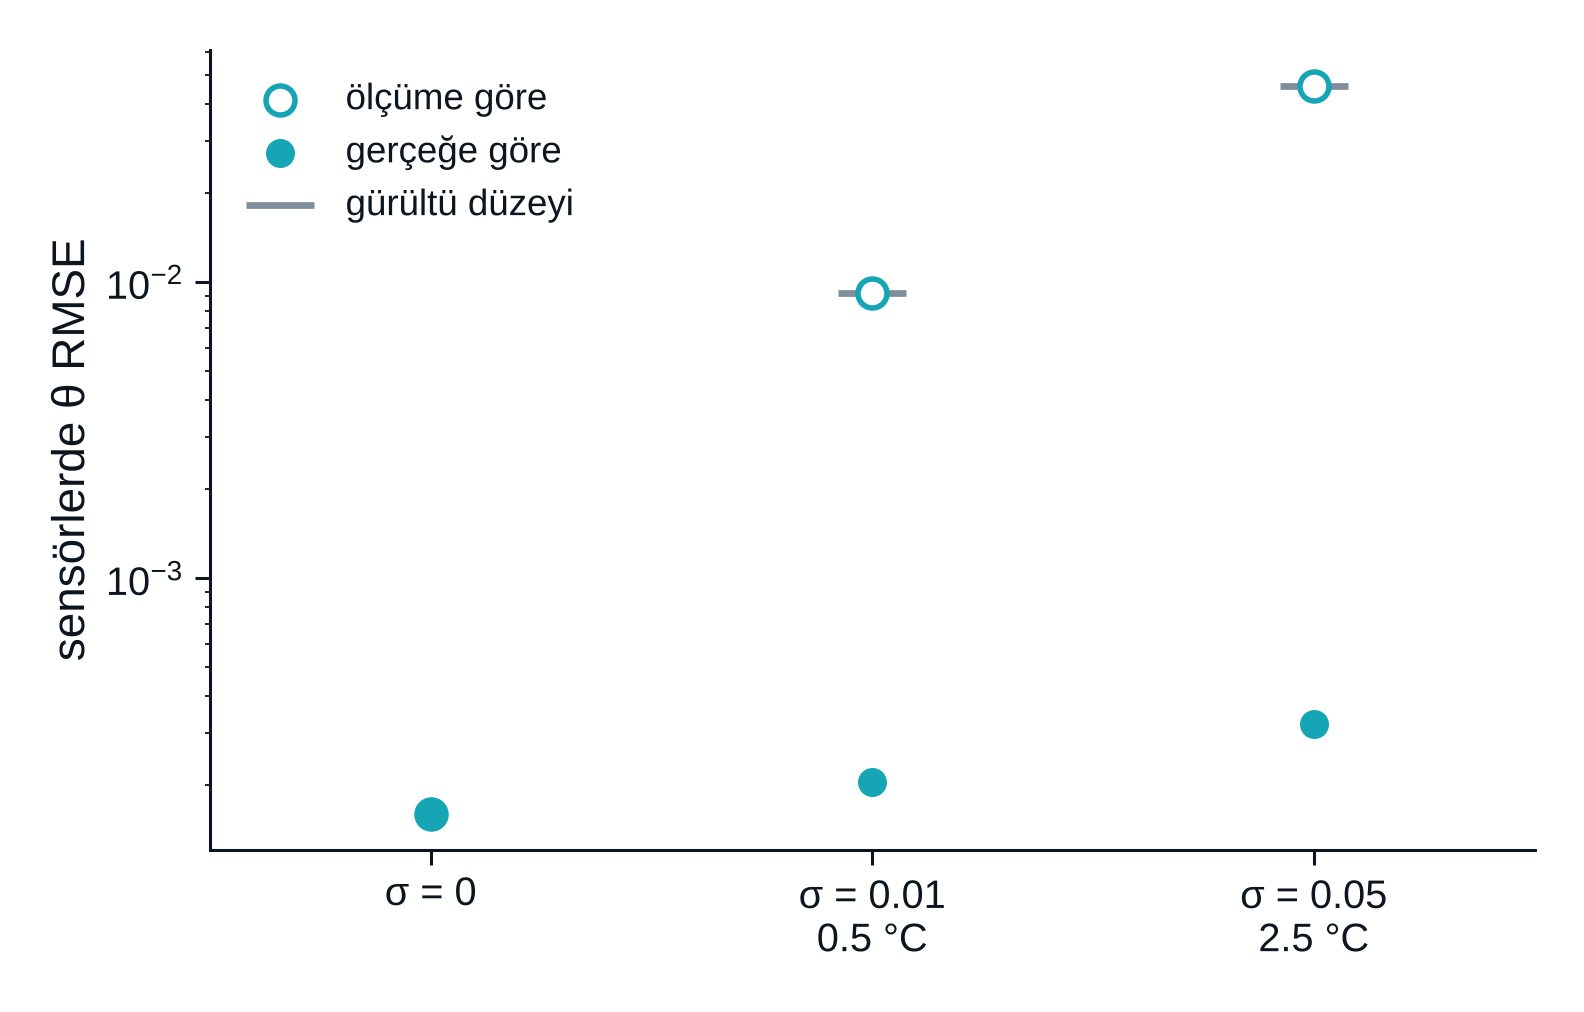

In [10]:
goster("04_noise.png", 620)

Ağ gürültüyü ezberlemiyor: ölçüme göre hata $\approx \sigma$, gerçeğe göre hata çok daha küçük. Laplace denklemi
düzgün bir çözüm dayatıyor ve rastgele sıçramaları süzüyor.

### 2.2 Verinin değeri: bilgi ölçütü *(yüksek lisans)*

$N_d$ bağımsız ölçümün ortalamasındaki belirsizlik $\sigma/\sqrt{N_d}$. Veri, ancak bu değer modelin kendi hatasından
küçükse yeni bilgi taşır:

$$\frac{\sigma}{\sqrt{N_d}} \;<\; \varepsilon_{\mathrm{model}} \quad\Rightarrow\quad \text{veri bilgi taşır}$$

In [11]:
eps_model = S["eps_model_no_data"]["gmean"]
print(f"veri yokken modelin RMS hatası (3 tohum, geo. ort.): ε_model ≈ {eps_model:.1e}")
for n in (5, 20, 80, 1000):
    print(f"N_d = {n:5d}: σ/√N_d = {sigma / np.sqrt(n):.1e}  ->  {'bilgi taşır' if sigma / np.sqrt(n) < eps_model else 'modelden daha belirsiz'}")
print(f"gereken sensör sayısı ≈ (σ / ε_model)² = {(sigma / eps_model)**2:.0f}")

veri yokken modelin RMS hatası (3 tohum, geo. ort.): ε_model ≈ 3.6e-04
N_d =     5: σ/√N_d = 4.5e-03  ->  modelden daha belirsiz
N_d =    20: σ/√N_d = 2.2e-03  ->  modelden daha belirsiz
N_d =    80: σ/√N_d = 1.1e-03  ->  modelden daha belirsiz
N_d =  1000: σ/√N_d = 3.2e-04  ->  bilgi taşır
gereken sensör sayısı ≈ (σ / ε_model)² = 758


---
## 3 · Yanlış fizik: veri ne zaman işe yarar?

Gerçek hayatta $\bar h$ korelasyondan gelir ve ±%20–30 belirsizdir. Burada uç bir durum kuruyoruz: model
$\mathrm{Bi} = 2$ sanıyor, ölçümler ise gerçek $\mathrm{Bi} = 4.895$'ten geliyor.

$$\mathcal{L}_{\mathrm{Robin}} = \frac{1}{N_b}\sum_{m}\Big(\frac{\partial\hat\theta}{\partial\eta} - 2\,\hat\theta\Big)^2,
\qquad \text{ölçümler: } \mathrm{Bi} = 4.895$$

In [12]:
_, m_y0 = egit(X_d[:0], y_d[:0], bi_model=2.0)              # yanlış fizik, veri yok
_, m_y1 = egit(X_d, y_d, mu=100.0, bi_model=2.0)            # yanlış fizik + 20 sensör, μ = 100
print(f"\nveri hatayı {m_y0['rel_L2'] / m_y1['rel_L2']:.1f} kat düşürdü (kısa eğitim)")

μ = 1, Bi_model = 2, N_d = 0:  L = 6.74e-02 (PDE 1.1e-02, Robin 5.6e-02, veri 0.0e+00) · bağıl L2 = 9.19e-02 · Q hatası %43.88 · 101 s


μ = 100, Bi_model = 2, N_d = 20:  L = 2.88e-01 (PDE 5.0e-02, Robin 1.1e-01, veri 1.2e-03) · bağıl L2 = 6.20e-02 · Q hatası %33.45 · 105 s

veri hatayı 1.5 kat düşürdü (kısa eğitim)


In [13]:
for g, v in S["wrong_bi"].items():
    print(f"{g:22s} bağıl L2 = {v['rel_L2']:.2e} · Q hatası %{100 * v['Q_rel_err']:5.1f}")
print(f"\ndoğru fizik, veri yok (tohum 0): bağıl L2 = {S['correct_physics_seed0']['rel_L2']:.2e}")

veri yok               bağıl L2 = 9.19e-02 · Q hatası % 43.8
20 sensör μ = 1        bağıl L2 = 9.13e-02 · Q hatası % 43.6
20 sensör μ = 100      bağıl L2 = 6.06e-02 · Q hatası % 32.0
80 sensör μ = 100      bağıl L2 = 4.62e-02 · Q hatası % 26.0

doğru fizik, veri yok (tohum 0): bağıl L2 = 9.54e-04


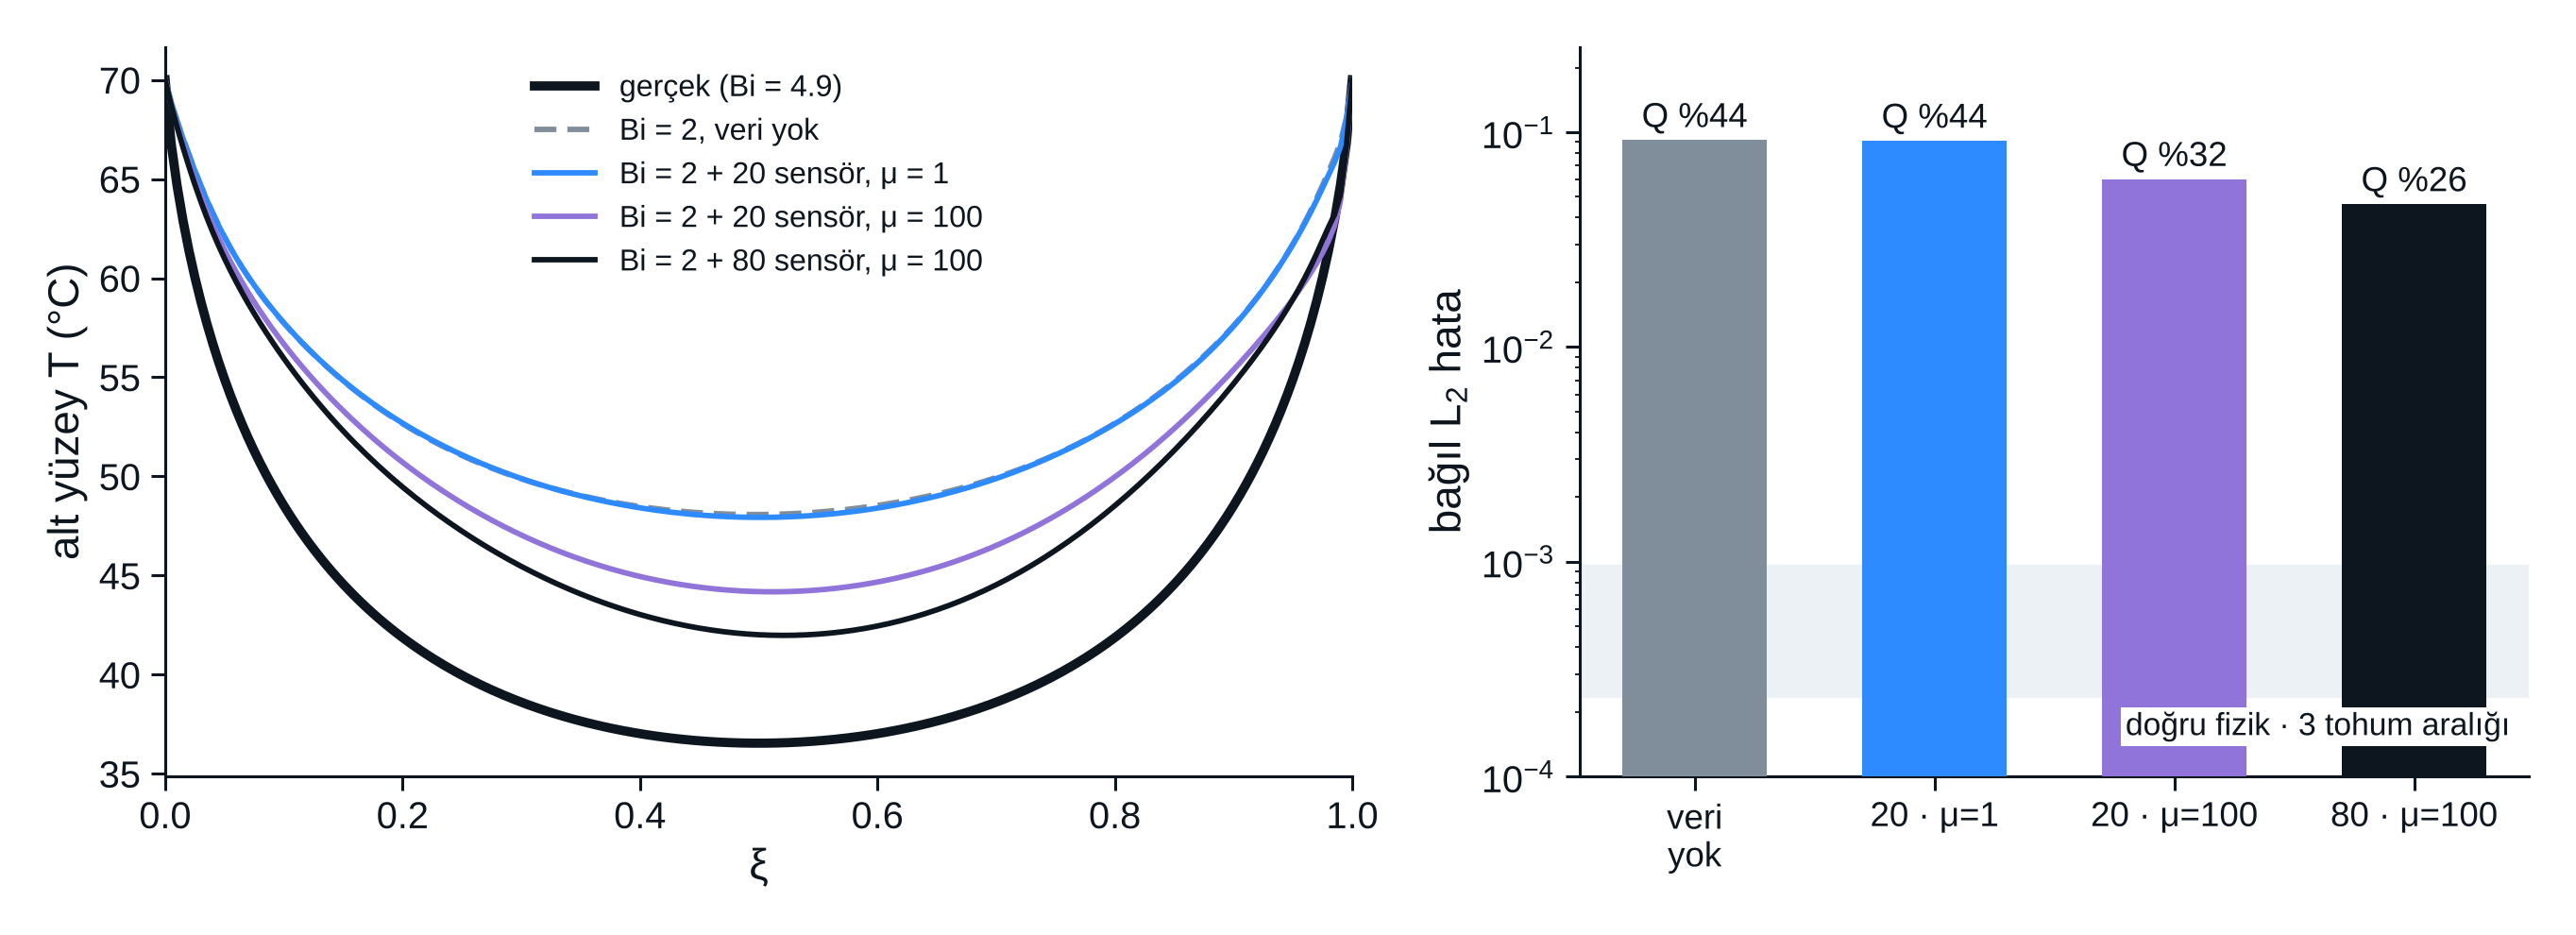

In [14]:
goster("05_wrong_bi.png", 900)

**Okuma.** Fizik yanlışken veri hatayı belirgin biçimde düşürüyor; ama doğru fiziğe ulaşamıyor, çünkü yanlış Robin
terimi ile ölçümler birbiriyle çekişiyor. Bu çekişmenin doğal çözümü Bi'yi de öğrenilecek bir parametre yapmak —
**Ders 04, ters problem**:

$$\min_{\mathbf{w},\,\mathrm{Bi}}\ \mathcal{L}_{\mathrm{PDE}} + \lambda\,\mathcal{L}_{\mathrm{Robin}}(\mathrm{Bi}) + \mu\,\mathcal{L}_{\mathrm{veri}}$$

## Özet

- Veri terimi tek satır: $\mu\,\mathrm{mean}(\hat\theta(\mathbf{x}_i) - \theta_i^{\mathrm{ö}})^2$. Ağırlığı kayıp terimlerinin ölçeğine bakarak seçin.
- Fizik doğru ve model hatası gürültüden çok küçükse veri bilgi taşımaz; sensör sayısı ve yerleşimi hatayı tohum aralığının dışına taşımadı, büyük μ zarar verdi.
- Fizik gürültüyü süzer: ağ ölçüme $\sigma$ kadar, gerçeğe çok daha yakın oturur.
- Fizik yanlışsa veri asıl işini görür; ama en iyisi bilinmeyeni öğrenmektir (Adım 7).

## Alıştırmalar

**Lisans:** (1) $\sigma = 0.001$ ile 20 sensör: bilgi ölçütüne göre veri artık işe yarar mı? Deneyin. ·
(2) $\mu = 0.1, 1, 10, 100$ taraması (doğru fizik) · (3) yanlış fizikte sensörleri yalnız alt şeride koyun.

**Yüksek lisans:** (1) $\mu$'yü kayıp terimlerinin gradyan büyüklüğüne göre otomatik ayarlayın (Wang vd. 2021) ·
(2) Bi_model = 3, 4, 6 için hatayı çizin · (3) Bi'yi `torch.nn.Parameter` yapıp ölçümlerden geri bulun — Ders 04'ün önizlemesi.

In [15]:
# Alıştırma alanı — Lisans 1: çok az gürültülü 20 sensör
X_c, y_c, _ = sensors(20, "uniform", 0.001, seed=0)
print(f"σ/√N_d = {0.001 / np.sqrt(20):.1e}  vs  ε_model ≈ {eps_model:.1e}")
# _, m_c = egit(X_c, y_c, mu=100.0)   # açıp çalıştırın (~2 dk)

σ/√N_d = 2.2e-04  vs  ε_model ≈ 3.6e-04
